# Baseline RoCoLe: mayoría, logística y Random Forest

Este cuaderno prueba si las siete medidas del EDA (ExG, NGRDI y GLCM, sin VARI) alcanzan a separar sana de afectada. Train aprende, val elige, test se mira al final. Esperamos poco por el solape del 03.


## Semilla fija

**Entrada:** ninguna.

**Qué hacemos:** fijamos la semilla del proyecto para que el azar del bosque (y lo que use aleatoriedad) se pueda repetir.

**Salida:** seed.


In [1]:
# Entrada
# ninguna

# Qué hacemos
seed = 42

# Salida
seed


42

## Ruta de características

**Entrada:** ninguna.

**Qué hacemos:** localizamos la tabla de características ya calculada en featured, relativa al repo.

**Salida:** features_path.


In [2]:
# Entrada
from pathlib import Path

# Qué hacemos
features_path = Path("../../data/featured/rocole/rgb_glcm_features.csv")

# Salida
print("features_path:", features_path.resolve())
print("existe:", features_path.exists())
features_path


features_path: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\data\featured\rocole\rgb_glcm_features.csv
existe: True


WindowsPath('../../data/featured/rocole/rgb_glcm_features.csv')

## Cargar la tabla featured

**Entrada:** features_path.

**Qué hacemos:** cargamos esa tabla. Conservamos File, split y link_group; no inventamos un reparto nuevo.

**Salida:** leaf_features.


In [3]:
# Entrada
import pandas as pd

# Qué hacemos
leaf_features = pd.read_csv(features_path)

# Salida
leaf_features.head()


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.261530,0.206835,0.141426,0.118705,0.210467,1.706653e-01,0.603388,0.798073,0.161943
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.167154,0.198152,0.082722,0.129672,-423.730733,1.340577e+06,0.739996,0.774939,0.139027
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.229394,0.264305,0.118196,0.141937,0.164238,2.007234e-01,0.638387,0.784853,0.147145
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.167927,0.147516,0.081697,0.085211,41580.329422,6.349106e+06,0.590025,0.785764,0.152910
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.253770,0.231036,0.118870,0.146720,127.325844,3.505966e+05,0.614583,0.805190,0.149165


## Inspección rápida

**Entrada:** leaf_features.

**Qué hacemos:** miramos de un vistazo columnas y tamaño, para confirmar que llegó el featured esperado.

**Salida:** ninguna (solo vista).


In [4]:
# Entrada
# leaf_features

# Qué hacemos
print("filas:", len(leaf_features))
print("columnas:", list(leaf_features.columns))

# Salida
leaf_features.info()


filas: 1481
columnas: ['File', 'split', 'link_group', 'Binary.Label', 'Multiclass.Label', 'error', 'exg_mean', 'exg_std', 'ngrdi_mean', 'ngrdi_std', 'vari_mean', 'vari_std', 'glcm_contrast', 'glcm_homogeneity', 'glcm_energy']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1481 entries, 0 to 1480
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   File              1481 non-null   object 
 1   split             1481 non-null   object 
 2   link_group        1481 non-null   int64  
 3   Binary.Label      1481 non-null   object 
 4   Multiclass.Label  1481 non-null   object 
 5   error             0 non-null      float64
 6   exg_mean          1481 non-null   float64
 7   exg_std           1481 non-null   float64
 8   ngrdi_mean        1481 non-null   float64
 9   ngrdi_std         1481 non-null   float64
 10  vari_mean         1481 non-null   float64
 11  vari_std          1481 non-null   float64
 12  glcm

## Conteos por etiqueta

**Entrada:** leaf_features.

**Qué hacemos:** contamos cuántas hojas hay por Binary.Label en toda la tabla (sana frente a afectada).

**Salida:** label_counts.


In [5]:
# Entrada
# leaf_features

# Qué hacemos
label_counts = leaf_features["Binary.Label"].value_counts()

# Salida
label_counts


Binary.Label
healthy      758
unhealthy    723
Name: count, dtype: int64

## Conteos por split

**Entrada:** leaf_features.

**Qué hacemos:** contamos cuántas hojas caen en train, val y test según la columna split ya guardada.

**Salida:** split_counts.


In [6]:
# Entrada
# leaf_features

# Qué hacemos
split_counts = leaf_features["split"].value_counts()

# Salida
split_counts


split
train    1037
test      226
val       218
Name: count, dtype: int64

## Siete medidas (sin VARI)

**Entrada:** ninguna.

**Qué hacemos:** listamos las siete medidas que usaremos: medias y desviaciones de ExG y NGRDI, más contraste, homogeneidad y energía GLCM. Sin VARI.

**Salida:** feature_columns.


In [7]:
# Entrada
# ninguna

# Qué hacemos
feature_columns = [
    "exg_mean",
    "exg_std",
    "ngrdi_mean",
    "ngrdi_std",
    "glcm_contrast",
    "glcm_homogeneity",
    "glcm_energy",
]

# Salida
feature_columns


['exg_mean',
 'exg_std',
 'ngrdi_mean',
 'ngrdi_std',
 'glcm_contrast',
 'glcm_homogeneity',
 'glcm_energy']

## Hojas de aprender

**Entrada:** leaf_features.

**Qué hacemos:** apartamos las hojas de aprender con split igual a train.

**Salida:** train_leaves.


In [8]:
# Entrada
# leaf_features

# Qué hacemos
train_leaves = leaf_features.loc[leaf_features["split"] == "train"].copy()

# Salida
print("train:", len(train_leaves))
train_leaves.head()


train: 1037


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.261530,0.206835,0.141426,0.118705,0.210467,1.706653e-01,0.603388,0.798073,0.161943
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.167154,0.198152,0.082722,0.129672,-423.730733,1.340577e+06,0.739996,0.774939,0.139027
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.229394,0.264305,0.118196,0.141937,0.164238,2.007234e-01,0.638387,0.784853,0.147145
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.167927,0.147516,0.081697,0.085211,41580.329422,6.349106e+06,0.590025,0.785764,0.152910
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.253770,0.231036,0.118870,0.146720,127.325844,3.505966e+05,0.614583,0.805190,0.149165


## Hojas de validación

**Entrada:** leaf_features.

**Qué hacemos:** apartamos las hojas de validación con split igual a val.

**Salida:** val_leaves.


In [9]:
# Entrada
# leaf_features

# Qué hacemos
val_leaves = leaf_features.loc[leaf_features["split"] == "val"].copy()

# Salida
print("val:", len(val_leaves))
val_leaves.head()


val: 218


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
17,C1P8E1.jpg,val,107,healthy,healthy,NaN,0.171819,0.196552,0.087104,0.116981,12122.387852,2.340099e+06,0.762372,0.770701,0.154178
18,C1P8H1.jpg,val,107,healthy,healthy,NaN,0.336084,0.313894,0.175372,0.164859,127.391027,2.684313e+05,1.120968,0.750552,0.160153
65,C1P32E2.jpg,val,98,unhealthy,rust_level_1,NaN,0.173216,0.180678,0.071529,0.094966,42.485449,5.562502e+05,0.674707,0.770774,0.139863
67,C1P32H2.jpg,val,98,unhealthy,rust_level_1,NaN,0.205515,0.248877,0.093423,0.129361,-1101.899648,4.871937e+05,1.341360,0.729064,0.122875
116,C2P12E1.jpg,val,112,healthy,healthy,NaN,0.197646,0.485022,0.037835,0.285851,-62794.598837,5.326934e+06,6.523397,0.601319,0.116535


## Hojas de prueba (guardadas)

**Entrada:** leaf_features.

**Qué hacemos:** apartamos las hojas de prueba con split igual a test y las dejamos guardadas hasta el final.

**Salida:** test_leaves.


In [10]:
# Entrada
# leaf_features

# Qué hacemos
test_leaves = leaf_features.loc[leaf_features["split"] == "test"].copy()

# Salida
print("test:", len(test_leaves))
test_leaves.head()


test: 226


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
10,C1P5E1.jpg,test,104,healthy,healthy,NaN,0.215536,0.188808,0.107566,0.100489,0.157597,1.440331e-01,0.561089,0.797121,0.167386
11,C1P5H1.jpg,test,104,healthy,healthy,NaN,0.323699,0.262964,0.159886,0.134594,0.218868,1.749060e-01,0.865290,0.770442,0.154805
38,C1P24E2.jpg,test,89,unhealthy,rust_level_2,NaN,0.181189,0.199428,0.063945,0.117125,222015.478507,1.168912e+07,0.583977,0.795235,0.151516
39,C1P24H2.jpg,test,89,unhealthy,rust_level_2,NaN,0.277066,0.220626,0.123859,0.114687,0.171236,1.571984e-01,0.737628,0.783143,0.148721
63,C1P31H2.jpg,test,97,unhealthy,rust_level_1,NaN,0.268206,0.232815,0.122069,0.115603,0.167436,1.595746e-01,0.561696,0.797368,0.159103


## Desbalance en train

**Entrada:** train_leaves.

**Qué hacemos:** contamos sanas y afectadas solo en train, para ver el desbalance que aprenderá el modelo.

**Salida:** train_label_counts.


In [11]:
# Entrada
# train_leaves

# Qué hacemos
train_label_counts = train_leaves["Binary.Label"].value_counts()

# Salida
train_label_counts


Binary.Label
healthy      530
unhealthy    507
Name: count, dtype: int64

## Etiquetas en val

**Entrada:** val_leaves.

**Qué hacemos:** contamos sanas y afectadas en val.

**Salida:** val_label_counts.


In [12]:
# Entrada
# val_leaves

# Qué hacemos
val_label_counts = val_leaves["Binary.Label"].value_counts()

# Salida
val_label_counts


Binary.Label
healthy      113
unhealthy    105
Name: count, dtype: int64

## Etiquetas en test (solo inventario)

**Entrada:** test_leaves.

**Qué hacemos:** contamos sanas y afectadas en test (solo inventario; aún no medimos acierto).

**Salida:** test_label_counts.


In [13]:
# Entrada
# test_leaves

# Qué hacemos
test_label_counts = test_leaves["Binary.Label"].value_counts()

# Salida
test_label_counts


Binary.Label
healthy      115
unhealthy    111
Name: count, dtype: int64

## Medidas de train

**Entrada:** train_leaves, feature_columns.

**Qué hacemos:** sacamos de train la matriz de las siete medidas, manteniendo el mismo orden de filas que las etiquetas.

**Salida:** train_features.


In [14]:
# Entrada
# train_leaves, feature_columns

# Qué hacemos
train_features = train_leaves[feature_columns].copy()

# Salida
print(train_features.shape)
train_features.head()


(1037, 7)


,exg_mean,exg_std,ngrdi_mean,ngrdi_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,0.261530,0.206835,0.141426,0.118705,0.603388,0.798073,0.161943
1,0.167154,0.198152,0.082722,0.129672,0.739996,0.774939,0.139027
2,0.229394,0.264305,0.118196,0.141937,0.638387,0.784853,0.147145
3,0.167927,0.147516,0.081697,0.085211,0.590025,0.785764,0.152910
4,0.253770,0.231036,0.118870,0.146720,0.614583,0.805190,0.149165


## Etiquetas de train

**Entrada:** train_leaves.

**Qué hacemos:** sacamos de train la etiqueta Binary.Label, en el mismo orden de filas.

**Salida:** train_labels.


In [15]:
# Entrada
# train_leaves

# Qué hacemos
train_labels = train_leaves["Binary.Label"].copy()

# Salida
print(train_labels.shape)
train_labels.head()


(1037,)


0      healthy
1    unhealthy
2      healthy
3      healthy
4    unhealthy
Name: Binary.Label, dtype: object

## Medidas de val

**Entrada:** val_leaves, feature_columns.

**Qué hacemos:** sacamos de val las siete medidas.

**Salida:** val_features.


In [16]:
# Entrada
# val_leaves, feature_columns

# Qué hacemos
val_features = val_leaves[feature_columns].copy()

# Salida
print(val_features.shape)
val_features.head()


(218, 7)


,exg_mean,exg_std,ngrdi_mean,ngrdi_std,glcm_contrast,glcm_homogeneity,glcm_energy
17,0.171819,0.196552,0.087104,0.116981,0.762372,0.770701,0.154178
18,0.336084,0.313894,0.175372,0.164859,1.120968,0.750552,0.160153
65,0.173216,0.180678,0.071529,0.094966,0.674707,0.770774,0.139863
67,0.205515,0.248877,0.093423,0.129361,1.341360,0.729064,0.122875
116,0.197646,0.485022,0.037835,0.285851,6.523397,0.601319,0.116535


## Etiquetas de val

**Entrada:** val_leaves.

**Qué hacemos:** sacamos de val la etiqueta Binary.Label.

**Salida:** val_labels.


In [17]:
# Entrada
# val_leaves

# Qué hacemos
val_labels = val_leaves["Binary.Label"].copy()

# Salida
print(val_labels.shape)
val_labels.head()


(218,)


17       healthy
18       healthy
65     unhealthy
67     unhealthy
116      healthy
Name: Binary.Label, dtype: object

## Medidas de test (sin mirar acierto)

**Entrada:** test_leaves, feature_columns.

**Qué hacemos:** sacamos de test las siete medidas y las dejamos sin mirar acierto.

**Salida:** test_features.


In [18]:
# Entrada
# test_leaves, feature_columns

# Qué hacemos
test_features = test_leaves[feature_columns].copy()

# Salida
print(test_features.shape)
test_features.head()


(226, 7)


,exg_mean,exg_std,ngrdi_mean,ngrdi_std,glcm_contrast,glcm_homogeneity,glcm_energy
10,0.215536,0.188808,0.107566,0.100489,0.561089,0.797121,0.167386
11,0.323699,0.262964,0.159886,0.134594,0.865290,0.770442,0.154805
38,0.181189,0.199428,0.063945,0.117125,0.583977,0.795235,0.151516
39,0.277066,0.220626,0.123859,0.114687,0.737628,0.783143,0.148721
63,0.268206,0.232815,0.122069,0.115603,0.561696,0.797368,0.159103


## Etiquetas de test

**Entrada:** test_leaves.

**Qué hacemos:** sacamos de test la etiqueta Binary.Label.

**Salida:** test_labels.


In [19]:
# Entrada
# test_leaves

# Qué hacemos
test_labels = test_leaves["Binary.Label"].copy()

# Salida
print(test_labels.shape)
test_labels.head()


(226,)


10      healthy
11      healthy
38    unhealthy
39    unhealthy
63    unhealthy
Name: Binary.Label, dtype: object

## Clasificador de mayoría

**Entrada:** train_features, train_labels.

**Qué hacemos:** como piso tonto, un clasificador de mayoría: siempre predice la clase más frecuente de train.

**Salida:** majority_model.


In [20]:
# Entrada
from sklearn.dummy import DummyClassifier

# Qué hacemos
majority_model = DummyClassifier(strategy="most_frequent")
majority_model.fit(train_features, train_labels)

# Salida
majority_model


,strategy,'most_frequent'
,random_state,None
,constant,None


## Mayoría en val

**Entrada:** majority_model, val_features, val_labels.

**Qué hacemos:** medimos ese piso en val (f1_macro y un reporte corto) para saber qué es “no saber nada”.

**Salida:** majority_val_metrics.


In [21]:
# Entrada
from sklearn.metrics import classification_report, f1_score

# Qué hacemos
majority_val_predictions = majority_model.predict(val_features)
majority_val_f1 = f1_score(val_labels, majority_val_predictions, average="macro")
majority_val_report = classification_report(val_labels, majority_val_predictions)
majority_val_metrics = {
    "f1_macro": majority_val_f1,
    "report": majority_val_report,
}

# Salida
print("f1_macro val (mayoría):", majority_val_metrics["f1_macro"])
print(majority_val_metrics["report"])
majority_val_metrics


f1_macro val (mayoría): 0.3413897280966767
              precision    recall  f1-score   support

     healthy       0.52      1.00      0.68       113
   unhealthy       0.00      0.00      0.00       105

    accuracy                           0.52       218
   macro avg       0.26      0.50      0.34       218
weighted avg       0.27      0.52      0.35       218



C:\Users\victo\.pyenv\pyenv-win\versions\3.10.5\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\victo\.pyenv\pyenv-win\versions\3.10.5\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\victo\.pyenv\pyenv-win\versions\3.10.5\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me

{'f1_macro': 0.3413897280966767,
 'report': '              precision    recall  f1-score   support\n\n     healthy       0.52      1.00      0.68       113\n   unhealthy       0.00      0.00      0.00       105\n\n    accuracy                           0.52       218\n   macro avg       0.26      0.50      0.34       218\nweighted avg       0.27      0.52      0.35       218\n'}

## Escalador (solo train)

**Entrada:** train_features.

**Qué hacemos:** ajustamos un escalador solo con las medidas de train (la logística es sensible a la escala).

**Salida:** feature_scaler.


In [22]:
# Entrada
from sklearn.preprocessing import StandardScaler

# Qué hacemos
feature_scaler = StandardScaler()
feature_scaler.fit(train_features)

# Salida
feature_scaler


,copy,True
,with_mean,True
,with_std,True


## Train escalado

**Entrada:** feature_scaler, train_features.

**Qué hacemos:** transformamos las medidas de train con ese escalador ya ajustado.

**Salida:** train_features_scaled.


In [23]:
# Entrada
# feature_scaler, train_features

# Qué hacemos
train_features_scaled = feature_scaler.transform(train_features)

# Salida
print(train_features_scaled.shape)
train_features_scaled


(1037, 7)


array([[-0.3964879 , -0.73165649,  0.330926  , ..., -0.44646314,
        -0.00728052, -0.02120396],
       [-1.06550059, -0.81325271, -0.54907804, ..., -0.38557572,
        -0.2988647 , -0.80579259],
       [-0.62429206, -0.19156394, -0.0173029 , ..., -0.43086364,
        -0.17391523, -0.5278489 ],
       ...,
       [ 1.32321038,  1.08459297,  1.26477132, ...,  1.69594718,
        -0.77798967, -0.24643641],
       [ 0.20785278,  0.99540822, -0.01386263, ..., -0.44473219,
         0.41101015, -0.11195466],
       [-0.09397074, -0.81309204, -0.48083343, ..., -0.16225179,
         0.05517417,  0.46208926]], shape=(1037, 7))

## Val escalado

**Entrada:** feature_scaler, val_features.

**Qué hacemos:** transformamos las medidas de val con el mismo escalador de train.

**Salida:** val_features_scaled.


In [24]:
# Entrada
# feature_scaler, val_features

# Qué hacemos
val_features_scaled = feature_scaler.transform(val_features)

# Salida
print(val_features_scaled.shape)
val_features_scaled


(218, 7)


array([[-1.03243434, -0.82829666, -0.48338161, ..., -0.37560208,
        -0.35229146, -0.28705338],
       [ 0.13200351,  0.27446364,  0.839784  , ..., -0.21577212,
        -0.6062541 , -0.08248879],
       [-1.02252977, -0.97747046, -0.71686615, ..., -0.41467538,
        -0.35137274, -0.77714573],
       ...,
       [-0.97648299, -1.04764455, -0.52086311, ..., -0.57227011,
         0.89710968,  0.94954903],
       [-0.44450334, -0.51039644,  0.20639521, ..., -0.54301414,
         0.67650551,  1.59226371],
       [ 0.193709  , -0.82770531,  0.67869425, ..., -0.33062375,
         0.40442367,  0.01456964]], shape=(218, 7))

## Rejilla corta de C (logística)

**Entrada:** train_features_scaled, train_labels, val_features_scaled, val_labels.

**Qué hacemos:** probamos en val unos pocos valores de C para la logística (rejilla corta).

**Salida:** logistic_val_scores.


In [25]:
# Entrada
from sklearn.linear_model import LogisticRegression

logistic_C_grid = [0.01, 0.1, 1, 10, 100]

# Qué hacemos
logistic_val_scores = []
for C in logistic_C_grid:
    candidate = LogisticRegression(
        C=C,
        class_weight="balanced",
        max_iter=1000,
        random_state=seed,
    )
    candidate.fit(train_features_scaled, train_labels)
    val_pred = candidate.predict(val_features_scaled)
    score = f1_score(val_labels, val_pred, average="macro")
    logistic_val_scores.append({"C": C, "f1_macro": score})

# Salida
logistic_val_scores


[{'C': 0.01, 'f1_macro': 0.5935593220338984},
 {'C': 0.1, 'f1_macro': 0.6174549144802216},
 {'C': 1, 'f1_macro': 0.6064396916084362},
 {'C': 10, 'f1_macro': 0.6014455782312925},
 {'C': 100, 'f1_macro': 0.6064396916084362}]

## Mejor C en val

**Entrada:** logistic_val_scores.

**Qué hacemos:** nos quedamos con el C que mejor f1_macro dio en val.

**Salida:** best_logistic_C.


In [26]:
# Entrada
# logistic_val_scores

# Qué hacemos
best_logistic_row = max(logistic_val_scores, key=lambda row: row["f1_macro"])
best_logistic_C = best_logistic_row["C"]

# Salida
print("mejor C:", best_logistic_C, "f1_macro val:", best_logistic_row["f1_macro"])
best_logistic_C


mejor C: 0.1 f1_macro val: 0.6174549144802216


0.1

## Logística final (train)

**Entrada:** train_features_scaled, train_labels, best_logistic_C.

**Qué hacemos:** reajustamos la logística final con ese C, solo sobre train escalado.

**Salida:** logistic_model.


In [27]:
# Entrada
# train_features_scaled, train_labels, best_logistic_C

# Qué hacemos
logistic_model = LogisticRegression(
    C=best_logistic_C,
    class_weight="balanced",
    max_iter=1000,
    random_state=seed,
)
logistic_model.fit(train_features_scaled, train_labels)

# Salida
logistic_model


,penalty,'l2'
,dual,False
,tol,0.0001
,C,0.1
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


## Logística en val

**Entrada:** logistic_model, val_features_scaled, val_labels.

**Qué hacemos:** guardamos las métricas de la logística en val (f1_macro y reporte).

**Salida:** logistic_val_metrics.


In [28]:
# Entrada
# logistic_model, val_features_scaled, val_labels

# Qué hacemos
logistic_val_predictions = logistic_model.predict(val_features_scaled)
logistic_val_f1 = f1_score(val_labels, logistic_val_predictions, average="macro")
logistic_val_report = classification_report(val_labels, logistic_val_predictions)
logistic_val_metrics = {
    "f1_macro": logistic_val_f1,
    "report": logistic_val_report,
}

# Salida
print("f1_macro val (logística):", logistic_val_metrics["f1_macro"])
print(logistic_val_metrics["report"])
logistic_val_metrics


f1_macro val (logística): 0.6174549144802216
              precision    recall  f1-score   support

     healthy       0.67      0.53      0.59       113
   unhealthy       0.59      0.71      0.64       105

    accuracy                           0.62       218
   macro avg       0.63      0.62      0.62       218
weighted avg       0.63      0.62      0.62       218



{'f1_macro': 0.6174549144802216,
 'report': '              precision    recall  f1-score   support\n\n     healthy       0.67      0.53      0.59       113\n   unhealthy       0.59      0.71      0.64       105\n\n    accuracy                           0.62       218\n   macro avg       0.63      0.62      0.62       218\nweighted avg       0.63      0.62      0.62       218\n'}

## Rejilla corta del bosque

**Entrada:** seed.

**Qué hacemos:** definimos una rejilla corta de n_estimators y max_depth para el bosque, con random_state igual a seed.

**Salida:** rf_param_grid.


In [29]:
# Entrada
# seed

# Qué hacemos
rf_param_grid = [
    {"n_estimators": n_estimators, "max_depth": max_depth, "random_state": seed}
    for n_estimators in [100, 200]
    for max_depth in [None, 5, 10]
]

# Salida
rf_param_grid


[{'n_estimators': 100, 'max_depth': None, 'random_state': 42},
 {'n_estimators': 100, 'max_depth': 5, 'random_state': 42},
 {'n_estimators': 100, 'max_depth': 10, 'random_state': 42},
 {'n_estimators': 200, 'max_depth': None, 'random_state': 42},
 {'n_estimators': 200, 'max_depth': 5, 'random_state': 42},
 {'n_estimators': 200, 'max_depth': 10, 'random_state': 42}]

## Probar el bosque en val

**Entrada:** train_features, train_labels, val_features, val_labels, rf_param_grid.

**Qué hacemos:** probamos cada par de la rejilla en val midiendo f1_macro (bosque sobre medidas sin escalar; el RF no necesita el escalador).

**Salida:** rf_val_scores.


In [30]:
# Entrada
from sklearn.ensemble import RandomForestClassifier

# Qué hacemos
rf_val_scores = []
for params in rf_param_grid:
    candidate = RandomForestClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        class_weight="balanced",
        random_state=params["random_state"],
    )
    candidate.fit(train_features, train_labels)
    val_pred = candidate.predict(val_features)
    score = f1_score(val_labels, val_pred, average="macro")
    rf_val_scores.append(
        {
            "n_estimators": params["n_estimators"],
            "max_depth": params["max_depth"],
            "f1_macro": score,
        }
    )

# Salida
rf_val_scores


[{'n_estimators': 100, 'max_depth': None, 'f1_macro': 0.6145491285678202},
 {'n_estimators': 100, 'max_depth': 5, 'f1_macro': 0.629251700680272},
 {'n_estimators': 100, 'max_depth': 10, 'f1_macro': 0.6038708586883029},
 {'n_estimators': 200, 'max_depth': None, 'f1_macro': 0.6280568720379147},
 {'n_estimators': 200, 'max_depth': 5, 'f1_macro': 0.6285251767913436},
 {'n_estimators': 200, 'max_depth': 10, 'f1_macro': 0.6222954699121028}]

## Mejores hiperparámetros del bosque

**Entrada:** rf_val_scores.

**Qué hacemos:** elegimos el par n_estimators y max_depth con mejor f1_macro en val.

**Salida:** best_rf_params.


In [31]:
# Entrada
# rf_val_scores

# Qué hacemos
best_rf_row = max(rf_val_scores, key=lambda row: row["f1_macro"])
best_rf_params = {
    "n_estimators": best_rf_row["n_estimators"],
    "max_depth": best_rf_row["max_depth"],
}

# Salida
print("mejores params:", best_rf_params, "f1_macro val:", best_rf_row["f1_macro"])
best_rf_params


mejores params: {'n_estimators': 100, 'max_depth': 5} f1_macro val: 0.629251700680272


{'n_estimators': 100, 'max_depth': 5}

## Bosque final (train)

**Entrada:** train_features, train_labels, best_rf_params, seed.

**Qué hacemos:** reajustamos el bosque final solo con train y esos hiperparámetros.

**Salida:** random_forest_model.


In [32]:
# Entrada
# train_features, train_labels, best_rf_params, seed

# Qué hacemos
random_forest_model = RandomForestClassifier(
    n_estimators=best_rf_params["n_estimators"],
    max_depth=best_rf_params["max_depth"],
    class_weight="balanced",
    random_state=seed,
)
random_forest_model.fit(train_features, train_labels)

# Salida
random_forest_model


,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## Bosque en val

**Entrada:** random_forest_model, val_features, val_labels.

**Qué hacemos:** guardamos las métricas del bosque en val.

**Salida:** rf_val_metrics.


In [33]:
# Entrada
# random_forest_model, val_features, val_labels

# Qué hacemos
rf_val_predictions = random_forest_model.predict(val_features)
rf_val_f1 = f1_score(val_labels, rf_val_predictions, average="macro")
rf_val_report = classification_report(val_labels, rf_val_predictions)
rf_val_metrics = {
    "f1_macro": rf_val_f1,
    "report": rf_val_report,
}

# Salida
print("f1_macro val (bosque):", rf_val_metrics["f1_macro"])
print(rf_val_metrics["report"])
rf_val_metrics


f1_macro val (bosque): 0.629251700680272
              precision    recall  f1-score   support

     healthy       0.70      0.51      0.59       113
   unhealthy       0.59      0.76      0.67       105

    accuracy                           0.63       218
   macro avg       0.65      0.64      0.63       218
weighted avg       0.65      0.63      0.63       218



{'f1_macro': 0.629251700680272,
 'report': '              precision    recall  f1-score   support\n\n     healthy       0.70      0.51      0.59       113\n   unhealthy       0.59      0.76      0.67       105\n\n    accuracy                           0.63       218\n   macro avg       0.65      0.64      0.63       218\nweighted avg       0.65      0.63      0.63       218\n'}

## Comparación en val

**Entrada:** majority_val_metrics, logistic_val_metrics, rf_val_metrics.

**Qué hacemos:** comparamos en una tablita pequeña el f1_macro de val: mayoría, logística y bosque. Solo para leer quién ganó la validación.

**Salida:** val_comparison.


In [34]:
# Entrada
# majority_val_metrics, logistic_val_metrics, rf_val_metrics

# Qué hacemos
val_comparison = pd.DataFrame(
    [
        {"modelo": "mayoria", "f1_macro_val": majority_val_metrics["f1_macro"]},
        {"modelo": "logistica", "f1_macro_val": logistic_val_metrics["f1_macro"]},
        {"modelo": "random_forest", "f1_macro_val": rf_val_metrics["f1_macro"]},
    ]
)

# Salida
val_comparison


,modelo,f1_macro_val
0,mayoria,0.341390
1,logistica,0.617455
2,random_forest,0.629252


## Test escalado

**Entrada:** feature_scaler, test_features.

**Qué hacemos:** ahora sí: escalamos test con el escalador de train (transform, sin refit).

**Salida:** test_features_scaled.


In [35]:
# Entrada
# feature_scaler, test_features

# Qué hacemos
test_features_scaled = feature_scaler.transform(test_features)

# Salida
print(test_features_scaled.shape)
test_features_scaled


(226, 7)


array([[-0.7225331 , -0.90106836, -0.17665353, ..., -0.46531643,
        -0.01927755,  0.1651256 ],
       [ 0.0442089 , -0.20416775,  0.60765354, ..., -0.32973049,
        -0.355546  , -0.26559722],
       [-0.96600871, -0.80126311, -0.83054635, ..., -0.45511465,
        -0.04305822, -0.37821161],
       ...,
       [ 0.07707609,  0.31187891,  0.28725958, ..., -0.56398527,
         0.93081848,  0.75095355],
       [ 0.05485912,  0.31843501,  0.60895766, ..., -0.62206553,
         1.31745783,  2.57357688],
       [ 2.53029512,  2.20614051,  2.34770849, ..., -0.53895686,
         0.72426974,  1.28670805]], shape=(226, 7))

## Predicción logística en test

**Entrada:** logistic_model, test_features_scaled.

**Qué hacemos:** predicción única de la logística en test.

**Salida:** logistic_test_predictions.


In [36]:
# Entrada
# logistic_model, test_features_scaled

# Qué hacemos
logistic_test_predictions = logistic_model.predict(test_features_scaled)

# Salida
logistic_test_predictions


array(['unhealthy', 'healthy', 'unhealthy', 'unhealthy', 'unhealthy',
       'healthy', 'unhealthy', 'healthy', 'healthy', 'healthy', 'healthy',
       'unhealthy', 'healthy', 'unhealthy', 'healthy', 'healthy',
       'healthy', 'healthy', 'healthy', 'healthy', 'healthy', 'healthy',
       'healthy', 'unhealthy', 'healthy', 'unhealthy', 'healthy',
       'healthy', 'unhealthy', 'healthy', 'healthy', 'healthy', 'healthy',
       'healthy', 'healthy', 'unhealthy', 'unhealthy', 'healthy',
       'healthy', 'healthy', 'healthy', 'unhealthy', 'healthy',
       'unhealthy', 'healthy', 'healthy', 'healthy', 'unhealthy',
       'unhealthy', 'unhealthy', 'healthy', 'unhealthy', 'unhealthy',
       'unhealthy', 'unhealthy', 'unhealthy', 'unhealthy', 'unhealthy',
       'unhealthy', 'unhealthy', 'healthy', 'unhealthy', 'healthy',
       'healthy', 'healthy', 'unhealthy', 'unhealthy', 'unhealthy',
       'unhealthy', 'unhealthy', 'unhealthy', 'healthy', 'unhealthy',
       'unhealthy', 'unhealthy'

## Métricas de logística en test

**Entrada:** test_labels, logistic_test_predictions.

**Qué hacemos:** reporte y matriz de confusión de la logística en test (una sola vez).

**Salida:** logistic_test_metrics.


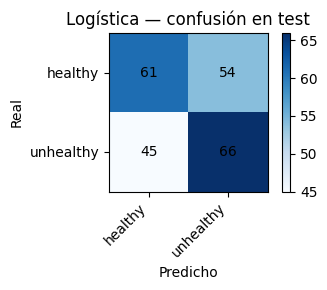

f1_macro test (logística): 0.561732385261797
              precision    recall  f1-score   support

     healthy       0.58      0.53      0.55       115
   unhealthy       0.55      0.59      0.57       111

    accuracy                           0.56       226
   macro avg       0.56      0.56      0.56       226
weighted avg       0.56      0.56      0.56       226

matriz de confusión:
 [[61 54]
 [45 66]]


{'f1_macro': 0.561732385261797,
 'report': '              precision    recall  f1-score   support\n\n     healthy       0.58      0.53      0.55       115\n   unhealthy       0.55      0.59      0.57       111\n\n    accuracy                           0.56       226\n   macro avg       0.56      0.56      0.56       226\nweighted avg       0.56      0.56      0.56       226\n',
 'confusion_matrix': array([[61, 54],
        [45, 66]])}

In [37]:
# Entrada
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Qué hacemos
logistic_test_f1 = f1_score(test_labels, logistic_test_predictions, average="macro")
logistic_test_report = classification_report(test_labels, logistic_test_predictions)
logistic_test_cm = confusion_matrix(test_labels, logistic_test_predictions)
logistic_test_metrics = {
    "f1_macro": logistic_test_f1,
    "report": logistic_test_report,
    "confusion_matrix": logistic_test_cm,
}

fig, ax = plt.subplots(figsize=(4, 3))
im = ax.imshow(logistic_test_cm, cmap="Blues")
ax.set_title("Logística — confusión en test")
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
labels = sorted(test_labels.unique())
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)
for i in range(logistic_test_cm.shape[0]):
    for j in range(logistic_test_cm.shape[1]):
        ax.text(j, i, int(logistic_test_cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

# Salida
print("f1_macro test (logística):", logistic_test_metrics["f1_macro"])
print(logistic_test_metrics["report"])
print("matriz de confusión:\n", logistic_test_metrics["confusion_matrix"])
logistic_test_metrics


## Predicción del bosque en test

**Entrada:** random_forest_model, test_features.

**Qué hacemos:** predicción única del bosque en test.

**Salida:** rf_test_predictions.


In [38]:
# Entrada
# random_forest_model, test_features

# Qué hacemos
rf_test_predictions = random_forest_model.predict(test_features)

# Salida
rf_test_predictions


array(['unhealthy', 'healthy', 'unhealthy', 'unhealthy', 'unhealthy',
       'healthy', 'unhealthy', 'healthy', 'unhealthy', 'healthy',
       'healthy', 'healthy', 'healthy', 'healthy', 'healthy', 'healthy',
       'healthy', 'healthy', 'healthy', 'healthy', 'healthy', 'healthy',
       'healthy', 'healthy', 'healthy', 'unhealthy', 'healthy', 'healthy',
       'healthy', 'healthy', 'healthy', 'unhealthy', 'healthy',
       'unhealthy', 'healthy', 'healthy', 'healthy', 'healthy',
       'unhealthy', 'healthy', 'healthy', 'unhealthy', 'healthy',
       'unhealthy', 'healthy', 'unhealthy', 'healthy', 'healthy',
       'healthy', 'unhealthy', 'unhealthy', 'unhealthy', 'unhealthy',
       'unhealthy', 'unhealthy', 'unhealthy', 'unhealthy', 'unhealthy',
       'unhealthy', 'unhealthy', 'healthy', 'unhealthy', 'healthy',
       'healthy', 'healthy', 'unhealthy', 'unhealthy', 'healthy',
       'unhealthy', 'unhealthy', 'unhealthy', 'healthy', 'unhealthy',
       'unhealthy', 'unhealthy', 'hea

## Métricas del bosque en test

**Entrada:** test_labels, rf_test_predictions.

**Qué hacemos:** reporte y matriz de confusión del bosque en test (una sola vez).

**Salida:** rf_test_metrics.


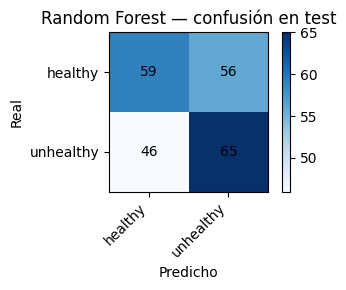

f1_macro test (bosque): 0.5483542319749216
              precision    recall  f1-score   support

     healthy       0.56      0.51      0.54       115
   unhealthy       0.54      0.59      0.56       111

    accuracy                           0.55       226
   macro avg       0.55      0.55      0.55       226
weighted avg       0.55      0.55      0.55       226

matriz de confusión:
 [[59 56]
 [46 65]]


{'f1_macro': 0.5483542319749216,
 'report': '              precision    recall  f1-score   support\n\n     healthy       0.56      0.51      0.54       115\n   unhealthy       0.54      0.59      0.56       111\n\n    accuracy                           0.55       226\n   macro avg       0.55      0.55      0.55       226\nweighted avg       0.55      0.55      0.55       226\n',
 'confusion_matrix': array([[59, 56],
        [46, 65]])}

In [39]:
# Entrada
# test_labels, rf_test_predictions

# Qué hacemos
rf_test_f1 = f1_score(test_labels, rf_test_predictions, average="macro")
rf_test_report = classification_report(test_labels, rf_test_predictions)
rf_test_cm = confusion_matrix(test_labels, rf_test_predictions)
rf_test_metrics = {
    "f1_macro": rf_test_f1,
    "report": rf_test_report,
    "confusion_matrix": rf_test_cm,
}

fig, ax = plt.subplots(figsize=(4, 3))
im = ax.imshow(rf_test_cm, cmap="Blues")
ax.set_title("Random Forest — confusión en test")
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
labels = sorted(test_labels.unique())
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)
for i in range(rf_test_cm.shape[0]):
    for j in range(rf_test_cm.shape[1]):
        ax.text(j, i, int(rf_test_cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

# Salida
print("f1_macro test (bosque):", rf_test_metrics["f1_macro"])
print(rf_test_metrics["report"])
print("matriz de confusión:\n", rf_test_metrics["confusion_matrix"])
rf_test_metrics


## Guardar resultados

**Entrada:** val_comparison, logistic_test_metrics, rf_test_metrics.

**Qué hacemos:** guardamos en experiments/results las métricas (y figuras de confusión si las hay) con nombres claros de RoCoLe baseline.

**Salida:** baseline_results_path.


In [40]:
# Entrada
# val_comparison, logistic_test_metrics, rf_test_metrics

# Qué hacemos
results_dir = Path("../../experiments/results")
results_dir.mkdir(parents=True, exist_ok=True)

baseline_results_path = results_dir / "rocole_baseline_metrics.csv"
val_comparison_path = results_dir / "rocole_baseline_val_comparison.csv"
logistic_cm_path = results_dir / "rocole_baseline_logistic_confusion.png"
rf_cm_path = results_dir / "rocole_baseline_rf_confusion.png"

val_comparison.to_csv(val_comparison_path, index=False)

test_metrics_table = pd.DataFrame(
    [
        {
            "modelo": "logistica",
            "f1_macro_test": logistic_test_metrics["f1_macro"],
            "best_C": best_logistic_C,
        },
        {
            "modelo": "random_forest",
            "f1_macro_test": rf_test_metrics["f1_macro"],
            "n_estimators": best_rf_params["n_estimators"],
            "max_depth": best_rf_params["max_depth"],
        },
    ]
)
test_metrics_table.to_csv(baseline_results_path, index=False)

fig, ax = plt.subplots(figsize=(4, 3))
im = ax.imshow(logistic_test_metrics["confusion_matrix"], cmap="Blues")
ax.set_title("Logística — confusión en test")
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
labels = sorted(test_labels.unique())
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)
cm = logistic_test_metrics["confusion_matrix"]
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(logistic_cm_path, dpi=150, bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(4, 3))
im = ax.imshow(rf_test_metrics["confusion_matrix"], cmap="Blues")
ax.set_title("Random Forest — confusión en test")
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)
cm = rf_test_metrics["confusion_matrix"]
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(rf_cm_path, dpi=150, bbox_inches="tight")
plt.close(fig)

# Salida
print("val:", val_comparison_path.resolve())
print("test metrics:", baseline_results_path.resolve())
print("cm logística:", logistic_cm_path.resolve())
print("cm bosque:", rf_cm_path.resolve())
baseline_results_path


val: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_val_comparison.csv
test metrics: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_metrics.csv
cm logística: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_logistic_confusion.png
cm bosque: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_rf_confusion.png


WindowsPath('../../experiments/results/rocole_baseline_metrics.csv')

## Conclusiones

Si el f1 apenas supera a la mayoría, encaja con el solape del 03: estas siete columnas no venden una solución sola.

Faltaría probar otras medidas o otro modelo, sin reabrir test hasta tener un candidato nuevo elegido otra vez solo con val.
